In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler
import seaborn as sns

In [2]:
peng = pd.read_csv('../../data/penguins.csv').dropna()
peng.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


# Part 1

### 1) 

In [3]:
model_peng = smf.ols('body_mass_g ~ flipper_length_mm + C(sex) + C(species)', data=peng).fit()
model_peng.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.867
Model:                            OLS   Adj. R-squared:                  0.865
Method:                 Least Squares   F-statistic:                     534.0
Date:                Tue, 29 Sep 2026   Prob (F-statistic):          3.37e-142
Time:                        18:32:51   Log-Likelihood:                -2364.4
No. Observations:                 333   AIC:                             4739.
Df Residuals:                     328   BIC:                             4758.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                -365.8174    532.050     -0.688      0.492   -1412.479     680.844
C(sex)[T.male]            530.3811     37.810     14.027      0.000     456.000     604.762
C(species)[T.Chinstrap]   -87.6345     46.347     -1.891      0.060    -178.810       3.541
C(species)[T.Gentoo]      836.2600     85.185      9.817      0.000     668.681    1003.839
flipper_length_mm          20.0249      2.846      7.037      0.000      14.427      25.623
==============================================================================
Omnibus:                        1.575   Durbin-Watson:                   2.097
Prob(Omnibus):                  0.455   Jarque-Bera (JB):                1.556
Skew:                           0.094   Prob(JB):                        0.459
Kurtosis:                       2.723   Cond. No.                     6.69e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.69e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

- The $R^2$ is 0.865 (adj) or 0.867 (regular)
- The coefficients for the model are:
    - Intercept: -365.82 
    - C(sex)[T.male]: 530.38
    - C(species)[T.Chinstrap]: -87.643
    - C(species)[T.Gentoo]: 836.26
    - flipper_length_mm: 20.02
- The reference level for sex is female and species is Adelie

### 2)

In [4]:
X = pd.get_dummies(peng[['flipper_length_mm', 'sex', 'species']],drop_first=True)
y = peng['body_mass_g']

X.head()

,flipper_length_mm,sex_male,species_Chinstrap,species_Gentoo
0,181.0,True,False,False
1,186.0,False,False,False
2,195.0,False,False,False
4,193.0,False,False,False
5,190.0,True,False,False


In [5]:
model_peng_sk = LinearRegression()
model_peng_sk.fit(X, y)
pd.Series(model_peng_sk.coef_, index=X.columns)

flipper_length_mm     20.024915
sex_male             530.381094
species_Chinstrap    -87.634478
species_Gentoo       836.260008
dtype: float64

In [6]:
print(model_peng_sk.intercept_)

-365.817449761581


In [7]:
model_peng_sk.score(X, y)

0.8668883562330879

All coefficients and $R^2$ match the statsmodels model

If we really want the confidence intervals for the coefficients personally I'd just build the same model in statsmodels and use theirs since the models are the same mathematically. Otherwise we could manually calculate the standard errors and build the confidence intervals manually but that seems tedious compared to the first method. 

### 3)

In [8]:
X = pd.get_dummies(peng[['flipper_length_mm', 'sex', 'species']])
model_peng_sk1 = LinearRegression(fit_intercept=True)
model_peng_sk1.fit(X, y)
pd.Series(model_peng_sk1.coef_, index=X.columns)

flipper_length_mm     20.024915
sex_female          -265.190547
sex_male             265.190547
species_Adelie      -249.541843
species_Chinstrap   -337.176321
species_Gentoo       586.718165
dtype: float64

In [9]:
model_peng_sk1.coef_

array([  20.02491543, -265.19054724,  265.19054724, -249.54184341,
       -337.17632133,  586.71816474])

In [10]:
model_peng_sk1.score(X, y)

0.866888356233088

- a) There's 6 coefficients instead of 4, which is expected with 2 categorical variables that are being dropped as the reference layer
- b) Yes, they're the same
- c) No the ones that exist in both models aren't the same. The difference in Chinstrap and Adelie is -87.63, Gentoo and Adelie is 836.26, and the male and female is -530. I noticed that the differences between the predictor's coefficient and the reference level (from the last model, which would be female and Adelie) predictor's coefficient are the dummy encoded model's coefficients for said predictor. I also noticed that if you sum up all of the one hot encoded coefficients they zero out.
- d) There is perfect multicollinearity between the categorical variables. We should be careful with encoding because it changes the interpretation of our coefficients.

### 4)

In [11]:
preprocessor = ColumnTransformer(transformers=[('numeric', 'passthrough', ['flipper_length_mm']),('categorical', OneHotEncoder(drop='first'), ['sex', 'species'])])
model_peng_sk2 = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())])

X = peng[['flipper_length_mm', 'sex', 'species']]

model_peng_sk2.fit(X, y)

model_peng_sk2['preprocessor'].get_feature_names_out()

array(['numeric__flipper_length_mm', 'categorical__sex_male',
       'categorical__species_Chinstrap', 'categorical__species_Gentoo'],
      dtype=object)

They're different names but they are the same as question 2 where female and adelie are the reference level

In [12]:
new_peng = pd.DataFrame({'flipper_length_mm': [215], 'sex': ['male'], 'species': ['Gentoo']})

model_peng_sk2.predict(new_peng)

array([5306.18047038])

In [13]:
-365.81 + (530.38 * 1) - (87.63 * 0) + (836.26 * 1) + (20.02 * 215)

5305.13

I used the coefficients from the statsmodels model, and they're essentially the same, I'm sure they'd be exactly the same if I didn't round to the hundredth's place. 

# Part 2

### 1) 

In [14]:
X = peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']]
y = peng['body_mass_g']

model = LinearRegression()
model.fit(X, y)
print(pd.Series(model.coef_, index=X.columns))

flipper_length_mm    50.762132
bill_length_mm        3.292863
bill_depth_mm        17.836391
dtype: float64


In [15]:
model.intercept_

np.float64(-6445.476043030193)

In [16]:
model.score(X, y)

0.7639366781169292

The coefficient for the intercept is -6445.48, flipper_length_mm is 50.76, bill_length_mm is 3.29, bill_depth_mm is 17.84 with the $R^2$ being 0.7639. 
- a) RFE would drop bill_length_mm

In [17]:
peng['bill_length_cm'] = peng['bill_length_mm'] /10
peng.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,bill_length_cm
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007,3.91
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007,3.95
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007,4.03
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007,3.67
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007,3.93


In [18]:
X = peng[['flipper_length_mm', 'bill_length_cm', 'bill_depth_mm']]

model1 = LinearRegression()
model1.fit(X, y)

print(pd.Series(model1.coef_, index=X.columns))

flipper_length_mm    50.762132
bill_length_cm       32.928625
bill_depth_mm        17.836391
dtype: float64


In [19]:
model1.intercept_

np.float64(-6445.476043030186)

In [20]:
model1.score(X, y)

0.7639366781169293

- b) The coefficients for flipper length and bill depth, were unchanged, but the coefficient for bill length was multiplied by a factor of 10 while $R^2$ remains unchanged. Now RFE would drop bill_depth_mm since it's the smallest absolute value of the 3 coefficients.

### 2) 

In [21]:
X = peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']]
model_std = make_pipeline(StandardScaler(), LinearRegression())
model_std.fit(X, y)

print(pd.Series(model_std[1].coef_, index=X.columns))

flipper_length_mm    710.401046
bill_length_mm        17.980514
bill_depth_mm         35.071275
dtype: float64


- a) A 1 standard deviation increase in flipper length is associated with increase of 710.4 grams in expected body mass
- b) The coefficients ranked by their absolute value are flipper length, bill depth, and bill length

In [22]:
X = peng[['flipper_length_mm', 'bill_length_cm', 'bill_depth_mm']]
model_std2 = make_pipeline(StandardScaler(), LinearRegression())
model_std2.fit(X, y)

print(pd.Series(model_std2[1].coef_, index=X.columns))

flipper_length_mm    710.401046
bill_length_cm        17.980514
bill_depth_mm         35.071275
dtype: float64


- b again) The standardization makes it so that changing the units from mm to cm has no effect on the model

In [23]:
X = peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']]
model_minmax = make_pipeline(MinMaxScaler(),LinearRegression())
model_minmax.fit(X, y)

print(pd.Series(model_minmax[1].coef_, index=X.columns))

flipper_length_mm    2994.965769
bill_length_mm         90.553720
bill_depth_mm         149.825685
dtype: float64


In [24]:
model_robust = make_pipeline(RobustScaler(), LinearRegression())
model_robust.fit(X, y)

print(pd.Series(model_robust[1].coef_, index=X.columns))

flipper_length_mm    1167.529028
bill_length_mm         29.965049
bill_depth_mm          55.292812
dtype: float64


- c) All of the scalers agree on the rankings, but not on the magnitudes of the coefficients since minmax transforms everything between 0 and 1 and robust is based on the median and IQR.

In [25]:
model_center = make_pipeline(StandardScaler(with_std=False), LinearRegression())
model_center.fit(X, y)

print(pd.Series(model_center[1].coef_, index=X.columns))
print("Intercept:", model_center[1].intercept_)
print("R²:", model_center.score(X, y))

flipper_length_mm    50.762132
bill_length_mm        3.292863
bill_depth_mm        17.836391
dtype: float64
Intercept: 4207.057057057057
R²: 0.7639366781169293


### 3) 

In [26]:
X_original = peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']]

X_cm = peng[['flipper_length_mm', 'bill_length_cm', 'bill_depth_mm']]

pred_original = model.predict(X_original)
pred_cm = model1.predict(X_cm)
pred_center = model_center.predict(X_original)
pred_std = model_std.predict(X_original)
pred_minmax = model_minmax.predict(X_original)

#Chat helped make the results dictionary, everything looks good in my comparison_df after checking each value
results = {
    'Original': {
        'coefficients': model.coef_,
        'intercept': model.intercept_,
        'R2': model.score(X_original, y),
        'predictions': pred_original
    },

    'Bill length cm': {
        'coefficients': model1.coef_,
        'intercept': model1.intercept_,
        'R2': model1.score(X_cm, y),
        'predictions': pred_cm
    },

    'Centered': {
        'coefficients': model_center[1].coef_,
        'intercept': model_center[1].intercept_,
        'R2': model_center.score(X_original, y),
        'predictions': pred_center
    },

    'StandardScaler': {
        'coefficients': model_std[1].coef_,
        'intercept': model_std[1].intercept_,
        'R2': model_std.score(X_original, y),
        'predictions': pred_std
    },

    'MinMaxScaler': {
        'coefficients': model_minmax[1].coef_,
        'intercept': model_minmax[1].intercept_,
        'R2': model_minmax.score(X_original, y),
        'predictions': pred_minmax
    }
}

for name, result in results.items():
    print('\n', name)
    print('Coefficients:', result['coefficients'])
    print('Intercept:', result['intercept'])
    print('R²:', result['R2'])


 Original
Coefficients: [50.76213167  3.29286254 17.83639105]
Intercept: -6445.476043030193
R²: 0.7639366781169292

 Bill length cm
Coefficients: [50.76213167 32.92862539 17.83639105]
Intercept: -6445.476043030186
R²: 0.7639366781169293

 Centered
Coefficients: [50.76213167  3.29286254 17.83639105]
Intercept: 4207.057057057057
R²: 0.7639366781169293

 StandardScaler
Coefficients: [710.40104637  17.98051439  35.07127531]
Intercept: 4207.057057057057
R²: 0.7639366781169294

 MinMaxScaler
Coefficients: [2994.9657686    90.55371981  149.82568479]
Intercept: 2624.9682146168634
R²: 0.7639366781169293


In [27]:
original = results['Original']

comparison = []

for name, result in results.items():
    comparison.append({'Model': name, 
                       'Coefficients changed': not np.allclose(result['coefficients'], original['coefficients']),
                       'Intercept changed': not np.isclose(result['intercept'], original['intercept']), 
                       'R2 changed': not np.isclose(result['R2'], original['R2']),
                       'Predictions changed': not np.allclose(result['predictions'],original['predictions'])})

comparison_df = pd.DataFrame(comparison)
comparison_df

,Model,Coefficients changed,Intercept changed,R2 changed,Predictions changed
0,Original,False,False,False,False
1,Bill length cm,True,False,False,False
2,Centered,False,True,False,False
3,StandardScaler,True,True,False,False
4,MinMaxScaler,True,True,False,False


In [28]:
scaler = StandardScaler()

X_standardized = pd.DataFrame(scaler.fit_transform(peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']]), columns=['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm'], index=peng.index)
X_standardized['body_mass_g'] = peng['body_mass_g']

sm_original = smf.ols('body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm', data=peng).fit()
sm_standardized = smf.ols('body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm', data=X_standardized).fit()

print("Original t-statistics:")
print(sm_original.tvalues)

print("\nStandardized t-statistics:")
print(sm_standardized.tvalues)

print("\nOriginal p-values:")
print(sm_original.pvalues)

print("\nStandardized p-values:")
print(sm_standardized.pvalues)

Original t-statistics:
Intercept           -11.385151
flipper_length_mm    20.327110
bill_length_mm        0.613661
bill_depth_mm         1.290067
dtype: float64

Standardized t-statistics:
Intercept            195.345261
flipper_length_mm     20.327110
bill_length_mm         0.613661
bill_depth_mm          1.290067
dtype: float64

Original p-values:
Intercept            1.526094e-25
flipper_length_mm    4.446424e-60
bill_length_mm       5.398636e-01
bill_depth_mm        1.979335e-01
dtype: float64

Standardized p-values:
Intercept            0.000000e+00
flipper_length_mm    4.446424e-60
bill_length_mm       5.398636e-01
bill_depth_mm        1.979335e-01
dtype: float64


- b) Linear scaling will affect the slopes of the coefficients but it doesn't change the statistical significance/power of the predictor

In [29]:
X_log = np.log(peng[['flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']])

model_log = LinearRegression()
model_log.fit(X_log, y)

print(pd.Series(model_log.coef_, index=X_log.columns))
print(model_log.intercept_)
print(model_log.score(X_log, y))

pred_log = model_log.predict(X_log)

results['Log predictors'] = {'coefficients': model_log.coef_, 'intercept': model_log.intercept_, 'R2': model_log.score(X_log, y), 'predictions': pred_log}

flipper_length_mm    10067.856945
bill_length_mm         220.567358
bill_depth_mm          221.549618
dtype: float64
-50621.33903419443
0.7554297411526653


- c) Since the log transformation isn't linear, the coefficients' slope and the $R^2$ change

### 4) 

In [30]:
bike = pd.read_csv('../../data/bike-sharing-daily.csv')
bike.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


<Axes: xlabel='casual', ylabel='Count'>

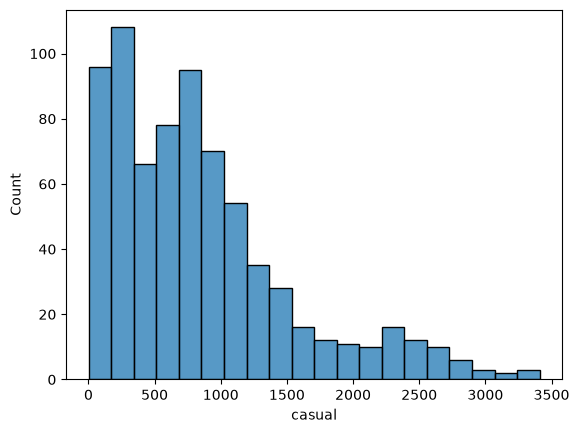

In [31]:
sns.histplot(data=bike, x='casual')

- a) The distribution is skewed heavily to the right with a median likely around the 1000 range. 

<Axes: ylabel='casual'>

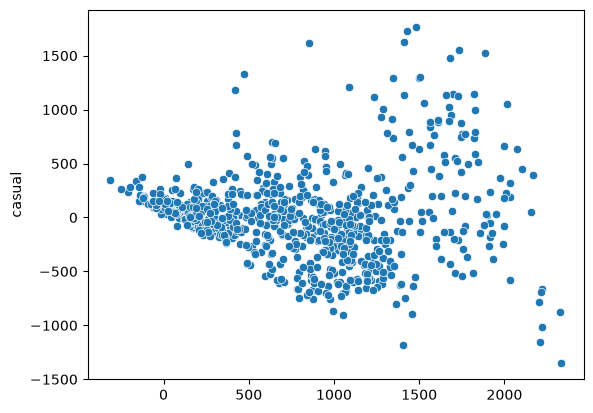

In [32]:
X_bike = bike[['temp', 'hum', 'windspeed', 'workingday']]
y_bike = bike['casual']

model_bike = LinearRegression()
model_bike.fit(X_bike, y_bike)

fitted_bike = model_bike.predict(X_bike)
residuals_bike = y_bike - fitted_bike

sns.scatterplot(x=fitted_bike, y=residuals_bike)

- b) There is definitely not constant variance among the residuals (heteroskedastic), with the variance exploding as the predicted value grows larger

<Axes: xlabel='casual', ylabel='Count'>

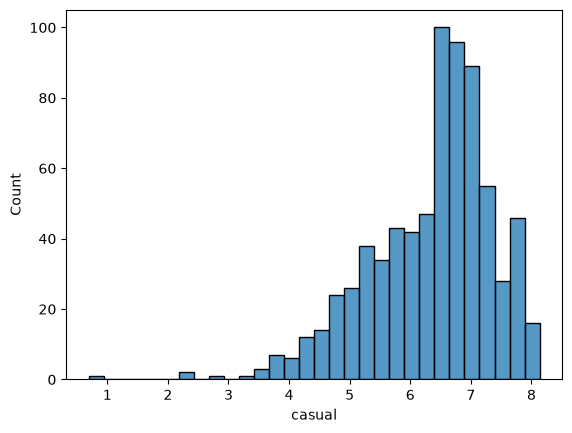

In [33]:
y_log = np.log(bike['casual'])

model_bike_log = LinearRegression()
model_bike_log.fit(X_bike, y_log)

fitted_bike_log = model_bike_log.predict(X_bike)
residuals_bike_log = y_log - fitted_bike_log

sns.histplot(x=y_log, bins=30)

<Axes: ylabel='casual'>

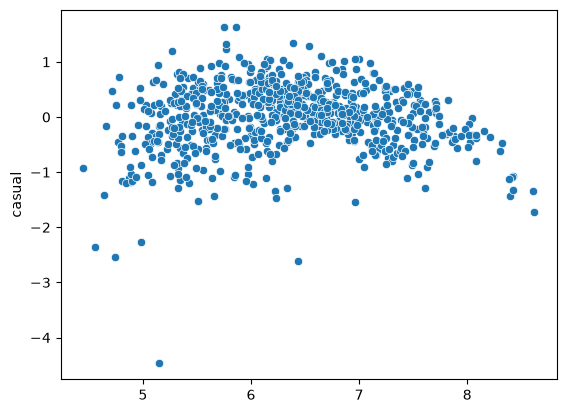

In [34]:
sns.scatterplot(x=fitted_bike_log, y=residuals_bike_log)

- c) After the log transformation, the amount of casual riders on a given day is now skewed left, although slightly more normal than before. Looking at the residuals, the exploding variance in the residuals is mostly fixed, but now the residuals are showing a sort of downward parabolic pattern indicating some nonlinearity in the data.

- d) Yes, looking at the histogram it made sense to use a log transformation on casual given the distribution was skewed to the right. It ended up making the heteroskedasticity a little bit better and the distribution more normal. I'd say it made improvements, but compared to the Kepler example where it lined up perfectly, running a log transformation on casual riders was not as effective